# 02. Fine-tuning and sweeps with Ray Train and Ray Tune

**AI Drug Discovery & Development Summit 2026 · Hands-on workshop · Part 2 of 3**

**Workshop series:** [01 Ray and offline inference](01_ray_and_offline_inference.ipynb) · [02 Train and tune](02_train_and_tune.ipynb) · [03 Serve](03_serve.ipynb)

Notebook 01 measured how a general co-folding model behaves on 3 real campaigns: strong on SARS-CoV-2 Mpro,
weak on EV-A71 2A. This notebook takes the general OpenFold3 145k model, fine-tunes it on 66 EV-A71 2A
fragment structures with Ray Train, and scores it on held-out follow-on compounds.

![Before and after fine-tuning](docs/images/before_after_accuracy.gif)

| § | Topic | Ray library | Min |
|---|---|---|---|
| 0 | Setup | | 2 |
| 5 | Fine-tuning OpenFold3 on fragment structures | Ray Train | 20 |
| A | Hyperparameter and inference sweeps | Ray Tune | |

Section numbers follow the workshop as a whole, so this notebook starts at Section 5.


## 0. Setup

- The Workspace runs the `aiddd-boltz2-of3` image: Ray, Boltz-2 and 2 OpenFold3 versions (0.5 and 0.4.3).
- This notebook runs on a CPU-only head node. L4 GPU nodes join when a cell requests a GPU and leave when idle.
- Data, model weights and all benchmark results live on shared storage.

In [34]:
import os, sys, json, time, warnings, subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import ray

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 60)

from aiddd_pipeline import (SHARED, TARGETS, BOLTZ_CACHE, OF3_OB_CKPT, OF3_P2_CKPT, OF3_FT_CKPT, OF3_LEGACY,
                            Boltz2Predictor, OF3Predictor, load_ligands, validate, make_scorer)
import workshop_helpers as wh

# Data and weights are downloaded once, ahead of the workshop (README step 2)
needed = [TARGETS[t].path("metadata") for t in wh.TARGET_KEYS] + [BOLTZ_CACHE, OF3_OB_CKPT, OF3_P2_CKPT, OF3_FT_CKPT]
missing = [str(p) for p in needed if not p.exists()]
assert not missing, f"Missing {missing}. Run `python scripts/setup_data.py` and `python scripts/prepare_mpro.py` first."

# True: run every GPU step live (the presenter, or anyone with their own GPUs).
# False: GPU steps load stored results. Serving is notebook 03.
USE_GPUS = False
SERVICE_URL = os.environ.get("AIDDD_SERVICE_URL", "")   # the deployed prediction service used in notebook 03
GPU = "L4"            # GPU type for every GPU step in this notebook

wh.MINE.mkdir(parents=True, exist_ok=True)
print(f"shared data:  {SHARED}")
print(f"your outputs: {wh.MINE}")

try:
    ray.init(runtime_env={"env_vars": {"AIDDD_SHARED": str(SHARED)}}, ignore_reinit_error=True, logging_level="ERROR")
except ValueError:   # inside an Anyscale Job, which already sets the environment
    ray.init(ignore_reinit_error=True, logging_level="ERROR")
dashboard = os.environ.get("RAY_OVERRIDE_DASHBOARD_URL") or ray.get_runtime_context().dashboard_url
print(f"Ray Dashboard metrics: {dashboard.rstrip('/')}/#/metrics   (open in a new browser tab)")

shared data:  /mnt/user_storage/aiddd
your outputs: /mnt/user_storage/aiddd/workshop/alicia_chua_30e1ffa
Ray Dashboard metrics: https://session-thqdxs9cduqis7hsp7r4mvd42v.i.anyscaleuserdata.com/#/metrics   (open in a new browser tab)


In [ ]:
# Benchmark results, built in notebook 01 Section 4 and loaded here so this notebook stands alone
results = {t: wh.load_results(t) for t in wh.TARGET_KEYS}
print("loaded benchmark results:", ", ".join(results))


## 5. Fine-tuning OpenFold3 on fragment structures with Ray Train

Fine-tuning a general model on 1 target's fragment screen costs about 2 hours on 8 GPUs. This section
covers what that buys, what it costs, and how many variants a team can try in a night.

⏱ **Budget: 20 minutes.** A full run cannot happen live, so a short run on the cluster is paired with
results produced in advance:

1. **5.1 to 5.3** The starting point, the training data and the code.
2. **5.4** A short live run on the cluster, about 10 minutes, demonstrating Ray Train.
3. **5.5** Fault tolerance when a node is lost mid-run.
4. **5.6 and 5.7** Results and cost of the full runs trained in advance.

### 5.1 Starting point

OpenFold3 145k is a capable general model on a target it has effectively seen before, and weak on a new target:

![Before and after fine-tuning](docs/images/before_after_accuracy.gif)

| Late follow-ons, % within 2 Å | SARS-CoV-2 Mpro | EV-A71 2A |
|---|---|---|
| OpenFold3 145k | 88% | **24%** |

### 5.2 Training data: 66 fragment structures

- **What:** the 66 curated EV-A71 2A fragment-screen complexes (protein, ligand and MSA).
- **Why fragments:** they come first in every campaign and are the cheapest structures to obtain.
- **What stays held out:** every follow-on compound. All 596 follow-ons in the evaluation are compounds the model
  never sees in training, so the result measures what a team could achieve early in a real campaign.
- **Same starting point and data as the OpenBind team's released fine-tune**, which makes the 2 directly comparable.

### 5.3 From OpenFold3 training to Ray Train

OpenFold3's own training stack (data module, losses, per-sample gradient clipping, EMA) runs **unchanged**.
Ray Train replaces the launcher (`torchrun` or SLURM) and adds the cluster:

```python
trainer = TorchTrainer(
    train_loop_per_worker,                    # OpenFold3's Lightning runner with RayDDPStrategy
    scaling_config=ScalingConfig(num_workers=8, use_gpu=True, accelerator_type="L4"),
    run_config=RunConfig(storage_path=...,
                         failure_config=FailureConfig(max_failures=2),        # survive lost nodes
                         checkpoint_config=CheckpointConfig(num_to_keep=1)))
result = trainer.fit()
```

| What Ray Train adds | Evidence from our runs |
|---|---|
| **Multi-node with 1 flag** | 2 → 8 GPUs is `--num-workers 8`. A step takes 7.6 s on 2 GPUs and ~8 s on 8 separate nodes: cross-node synchronization is nearly free |
| **Observability** | Every step reports loss, protein–ligand lDDT, step time, GPU memory (13.2 GB of 24) and GPU utilization (~81%) |
| **Fault tolerance** | Lost workers are restarted automatically; with checkpoints every 100 steps, training resumes where it stopped (5.5) |
| **Any GPU, any zone** | The same script ran on L4 and L40S, across availability zones, on spot or on-demand capacity |
| **Older software stacks** | 145k loads only in OpenFold3 0.4.3; Ray runs the workers in that environment via `runtime_env={"py_executable": ...}` |

<img src="docs/images/ray/train-overview.png" alt="Ray Train" width="560">
<sub>Diagram: Ray documentation, docs.ray.io (Apache 2.0).</sub>

### 5.4 A short fine-tune on the cluster

⏱ **~10 minutes** with warm GPU nodes: `FT_STEPS` steps on `FT_GPUS` L4 GPUs, starting from OpenFold3 145k.

- Each line is 1 optimizer step, averaged over all workers.
- Set `FT_DEMO_FAILURE = True` to crash the run on purpose at step 25 and watch Ray Train resume from the
  checkpoint at step 20.
- With `USE_GPUS = False` the cell skips training; the plot below shows the full recorded run.

In [56]:
RUN_FINETUNE = USE_GPUS
FT_GPUS, FT_STEPS = 4, 40
FT_DEMO_FAILURE = False

live_run = None
if RUN_FINETUNE:
    live_run = f"workshop-{wh.USER}-{time.strftime('%H%M%S')}"
    cmd = [sys.executable, "finetune_ray_train.py", "--base", "p2", "--accelerator", GPU,
           "--num-workers", str(FT_GPUS), "--max-steps", str(FT_STEPS), "--checkpoint-every", "20",
           "--storage", str(wh.MINE / "finetune"), "--name", live_run]
    if FT_DEMO_FAILURE:
        cmd += ["--fail-at-step", "25"]
    # finetune_ray_train.py moves itself into OpenFold3 0.4.3 for the 145k base; stream its progress here
    proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
                            env={**os.environ, "AIDDD_SHARED": str(SHARED)})
    for line in proc.stdout:
        if any(k in line for k in (" step ", "Resuming", "simulated failure", "Done in", "weights:", "run ")):
            print(line.rstrip()[-140:], flush=True)
    proc.wait()
else:
    print("USE_GPUS is False: the plot below shows the full recorded run.")

USE_GPUS is False: the plot below shows the full recorded run.


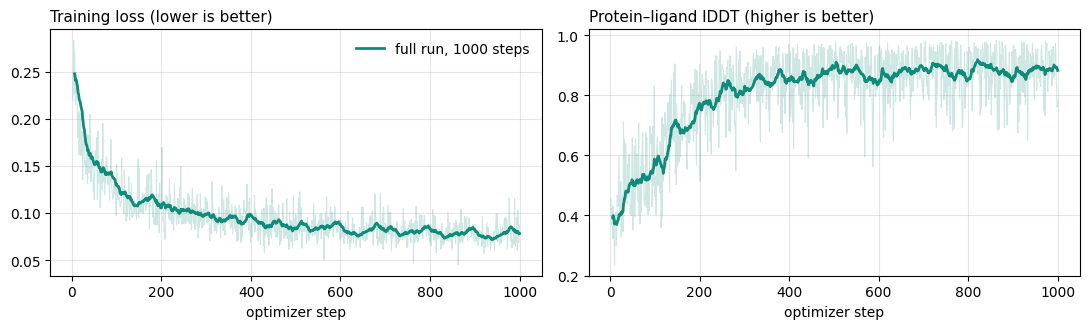

In [57]:
import matplotlib.pyplot as plt

full = wh.loss_curve(wh.ours_run())
yours = None
if live_run:
    found = sorted((wh.MINE / "finetune" / live_run).glob("checkpoint_*/loss_curve.json"))
    yours = pd.DataFrame(json.loads(found[-1].read_text())) if found else None

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, col, name in zip(axes, ["loss", "lddt_inter_protein_ligand_step"],
                         ["Training loss (lower is better)", "Protein–ligand lDDT (higher is better)"]):
    if full is not None:
        r = full[full.step > 1]
        ax.plot(r.step, r[col], color=wh.COLORS["of3ray"], alpha=0.2, lw=0.8)
        ax.plot(r.step, r[col].rolling(20, min_periods=5).mean(), color=wh.COLORS["of3ray"], lw=2,
                label=f"full run, {int(r.step.max())} steps")
    if yours is not None:
        y = yours[yours.step > 1]
        ax.plot(y.step, y[col], "o-", color="#B3412E", ms=3, lw=1.2, label=f"your run, {int(y.step.max())} steps")
    ax.set_title(name, loc="left", fontsize=11)
    ax.set_xlabel("optimizer step")
    ax.grid(alpha=0.3)
axes[0].legend(frameon=False)
plt.tight_layout()

### 5.5 Fault tolerance under spot capacity

During preparation, a spot instance supporting 1 of the 8 GPUs was reclaimed at step 700 of a 1,000-step
run. Ray Train detected the loss and restarted the worker group automatically:

```
Training was interrupted by node preemption (preempted_ranks=[2])
[State Transition] PREEMPTING -> RESTARTING
```

- **Before:** weights were saved only at the end, so the restart began again at step 0, losing about 1.5 hours.
- **After:** the script reports a checkpoint every 100 steps. A restarted worker calls `ray.train.get_checkpoint()`,
  loads the latest weights, resumes the learning-rate schedule and trains only the remaining steps. At most
  100 steps, about 13 minutes, are repeated, and each checkpoint costs about 8 seconds.

```python
resume = ray.train.get_checkpoint()            # None on a fresh start
if resume:
    start_step = json.loads((Path(resume.to_directory()) / "resume.json").read_text())["step"]
...
ray.train.report(metrics, checkpoint=ray.train.Checkpoint.from_directory(tmp))   # every 100 steps
```

<img src="docs/images/train_recovery.png" alt="8 GPU workers losing a node and resuming from the last checkpoint" width="860">

**This is what made the results in 5.6 possible.** The 4 fine-tuning runs below were trained on **spot**
GPUs. Between them they lost 9 nodes to reclamation and finished every run, because a lost node
costs 100 steps rather than the whole job. On-demand capacity for the same work would have cost roughly
3 times as much.

### 5.6 Results before and after fine-tuning

Every run below starts from OpenFold3 145k and is scored on the 306 **late follow-on** compounds, none of
which appear in any training set.

| Run | Training data | Wall time | Late follow-ons within 2 Å |
|---|---|---|---|
| OpenFold3 145k, before | | | **23.9%** |
| Fine-tuned here, 8 diffusion samples per step | 66 fragments | 2.4 h on 8 L4 | **44.8%** |
| Fine-tuned here, 32 diffusion samples per step | 80 fragments | 3.7 h on 8 L4 | 40.6% |
| OpenBind team's released checkpoint | about 79 fragments | not run here | 78.1% |

**Observations**

- **Fine-tuning on the fragment screen nearly doubles accuracy on held-out compounds**, from 23.9% to 44.8%,
  for about 2.5 hours on 8 GPUs. On the latest fifth of the campaign, the hardest compounds of all, it goes
  from 12.8% to 34.3%.
- **4 times the sampling per step did not help**, so the remaining distance to the released checkpoint is not
  training compute. Reproducing a published checkpoint exactly is a separate exercise; what matters here is
  that a team can run this experiment on its own target in an afternoon.
- **Fine-tuning beats extra inference compute.** Predicting 5 poses per compound instead of 1 lifts the base
  model from 23.9% to 32.7%, while the fine-tuned model stays where it was (44.8% with 1 pose, 43.8% with 5).
  At 5 poses each the comparison is 32.7% against 43.8%, on 8 L4 GPUs in 35 to 39 minutes per model.
- **A fine-tuned model is a specialist.** On the 2 proteases it was not trained for, it gives up some accuracy:
  62.1% on SARS-CoV-2 and 68.8% on MERS-CoV, against 87.7% and 73.5% for the general model.

In [58]:
print(f"Our fine-tune: {wh.ours_run() or 'not benchmarked yet'}")
wh.before_after(results).style.format(lambda v: v if isinstance(v, str) else f"{v:.1f}") \
  .set_caption("Late follow-ons: share of poses within 2 Å (%)")

Our fine-tune: ft-p2-evfrag80-1000s-8g-32samp-1023-0203


,EV-A71 2A protease (late follow-ons),SARS-CoV-2 Mpro (late follow-ons),MERS-CoV Mpro (late follow-ons)
OpenFold3 145k (general),23.9,87.7,73.5
Fine-tuned with Ray Train,40.6,65.2,71.0
OpenBind fine-tune (released),78.1,56.5,66.4


**Interpretation**

- **EV-A71 2A column:** the effect of fine-tuning on held-out compounds of the target it was trained for.
- **SARS-CoV-2 and MERS-CoV columns:** a check on the targets it was *not* trained for. The released fine-tune
  drops there (88% → 57% on SARS-CoV-2): a fine-tuned model is a specialist for its own target.
- Rows marked *pending* fill in automatically once that run has been scored.

The same late follow-on compound before and after fine-tuning:

![The same compound before and after fine-tuning](docs/images/before_after_pose.gif)


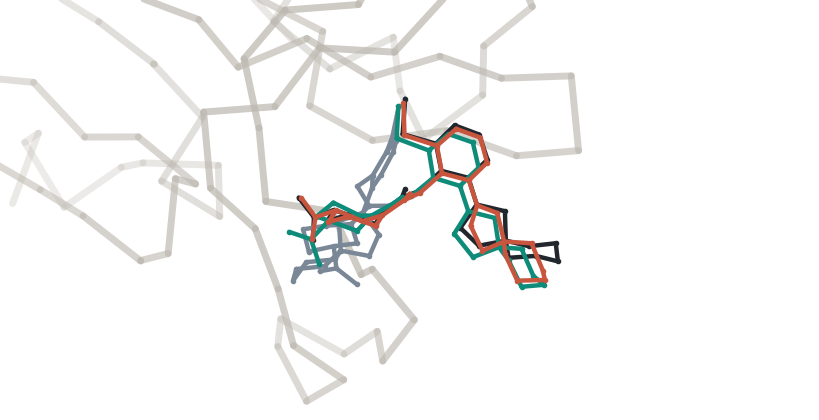

In [59]:
# x7101a, a late follow-on: slate = 145k, teal = our fine-tune, red = OpenBind release, dark = crystal
row = results["ev71-2a"].query("complex_name == 'A71EV2A-x7101a'").iloc[0]
wh.show_complex(row, models=("of3p2", "of3ray", "of3ft"))

### 5.7 The iteration loop

The point of the table above is not any single number. It is that 4 fine-tuning variants, 2 inference
settings and 3 target benchmarks came from 1 script with different flags, run on spot capacity by 1 person
in a single working session.

| In 1 working session | Count |
|---|---|
| Fine-tuning runs | 4 (66 and 80 fragments, 8 and 32 samples, 2 learning-rate settings) |
| Benchmark jobs | 9 (3 checkpoints across 3 targets) |
| Nodes lost to spot reclamation | 9 |
| Runs lost | 0 |
| Change required per variant | 1 command-line flag |

```bash
# fine-tune, then score the result on every target
anyscale job submit -f jobs/job.yaml --name ft-p2-evfrag -- \
  python finetune_ray_train.py --base p2 --num-workers 8 --max-steps 1000 --checkpoint-every 100
python scripts/bench_checkpoints.py --runs <run name> --targets ev71-2a,sars2-mpro,mers-mpro
```

Scaling up is `--num-workers`, a different GPU is `--accelerator`, and a different training set is `--data`.
Nothing in the OpenFold3 training code changes.

## Appendix A. Hyperparameter and inference sweeps with Ray Tune

Ray Tune runs many trials in parallel and stops the ones that fall behind. Both sweeps ran before the
workshop: `scripts/tune_finetune.py` (35 minutes on 4 L4 GPUs) and `scripts/tune_boltz.py` (62 minutes on 8 L4 GPUs).

<img src="docs/images/ray/tune_flow.png" alt="Ray Tune" width="620">
<sub>Diagram: Ray documentation, docs.ray.io (Apache 2.0).</sub>

**Sweep 1: learning rate.** Each trial is a full Ray Train run starting from OpenBind-0. The ASHA scheduler stops
trials whose lDDT falls behind; the survivor is scored on 32 held-out early follow-on complexes.

In [65]:
lr = pd.read_csv(SHARED / "finetune" / "runs" / "tune-of3-ev71" / "summary.csv")
lr["result"] = np.where(lr.val_success.notna(),
                        (100 * lr.val_success).round(1).astype(str) + "% within 2 Å on held-out compounds",
                        "stopped by ASHA at step " + lr.steps.astype(int).astype(str))
lr[["lr", "steps", "lddt_avg20", "result"]].style.format({"lr": "{:.0e}", "lddt_avg20": "{:.3f}"}).hide()

lr,steps,lddt_avg20,result
3e-05,120,0.381,stopped by ASHA at step 120
1e-04,120,0.428,stopped by ASHA at step 120
3e-04,150,0.590,93.8% within 2 Å on held-out compounds
1e-03,60,0.386,stopped by ASHA at step 60


ASHA stopped 3 of 4 trials early, so the sweep used about 450 GPU-steps instead of 600.

**Sweep 2: Boltz-2 inference settings on EV-A71 2A.** Each trial is 1 combination of recycling steps, diffusion
samples and steering; all 8 ran at once on 8 L4 GPUs.

In [66]:
bz = pd.read_csv(SHARED / "tune" / "runs" / "tune-boltz2-ev71" / "summary.csv")
bz["% within 2 Å"] = (100 * bz.success).round(1)
bz["GPU minutes"] = bz.minutes.round(0)
(bz[["setting", "% within 2 Å", "median_rmsd", "GPU minutes"]].rename(columns={"median_rmsd": "median RMSD (Å)"})
   .style.format({"% within 2 Å": "{:.1f}", "median RMSD (Å)": "{:.1f}", "GPU minutes": "{:.0f}"}).bar(subset=["% within 2 Å"], color="#9fb6cf", vmin=0, vmax=100).hide())

setting,% within 2 Å,median RMSD (Å),GPU minutes
rec10_samples5_steered,13.5,3.9,47
rec10_samples5,10.8,3.4,17
rec10_samples1_steered,2.7,3.9,26
rec10_samples1,2.7,4.0,11
rec3_samples1_steered,0.0,3.9,21
rec3_samples5,0.0,4.1,15
rec3_samples5_steered,0.0,4.1,46
rec3_samples1,0.0,4.3,8


The best setting lifts Boltz-2 from 0% to 13.5% at about 6 times the GPU cost. On this target, the choice of
model and fine-tuning matter far more than extra inference compute.